# Minggu 4: Praktikum 1 - K-Means Clustering


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('../datasetPBL/Transactions.csv')
df['Hour'] = pd.to_datetime(df['Time'], format='%H:%M:%S').dt.hour

# Pilih fitur
X = df[['NetSales', 'Hour']]

# Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

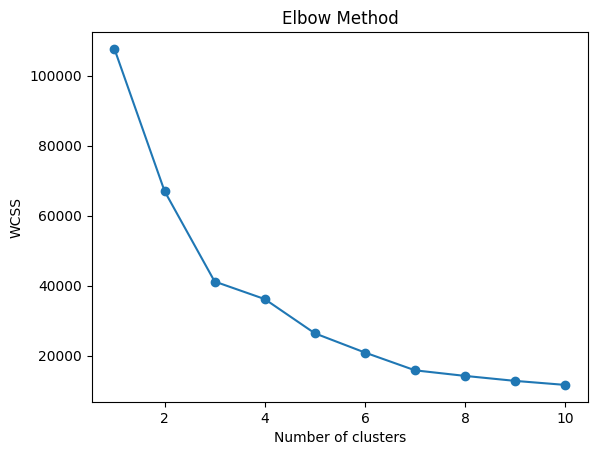

In [5]:
# Elbow Method
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

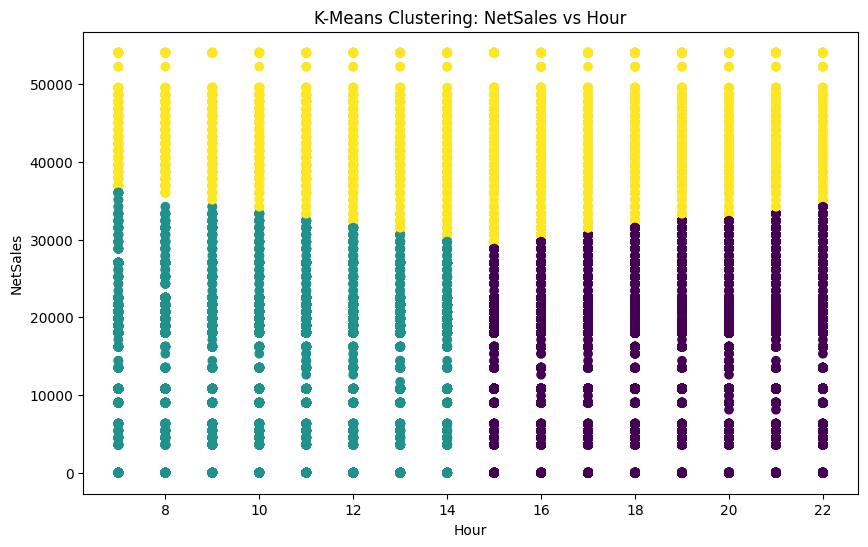

In [6]:
# Final K-Means (K=3)
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(10,6))
plt.scatter(df['Hour'], df['NetSales'], c=df['Cluster'], cmap='viridis')
plt.title('K-Means Clustering: NetSales vs Hour')
plt.xlabel('Hour')
plt.ylabel('NetSales')
plt.show()